In [1]:
import gymnasium as gym
from PPO.PPO import PPO
from PPO.PPO import run_test_env

In [2]:
# HYPER-PARAMETERS #
max_frames       = int(1e6)
max_rewards      = 500
num_steps        = 32
num_envs         = 16
batch_size       = 64
ppo_epochs       = 8
lr               = 'lin_5e-4'
clip_range       = 0.1
vf_coef          = 0.5
ent_coef         = 0.01
gamma            = 0.99
lam              = 0.8
clip_grad_norm   = 0.5
std_decay        = False
clip_log_std     = None
log_every        = 10
runs_for_episode = 1
test_episodes    = 10
log_file         = './logs/CartPole-v1.pth'

In [3]:
def make_env(render_mode=None):
    def _thunk():
        env = gym.make('CartPole-v1', render_mode=render_mode)
        return env
    return _thunk

def make_test_env():
    return None

In [4]:
ppo = PPO(make_env, device='auto')

In [ ]:
# Run this cell to load a previous checkpoint
ppo.load(log_file)

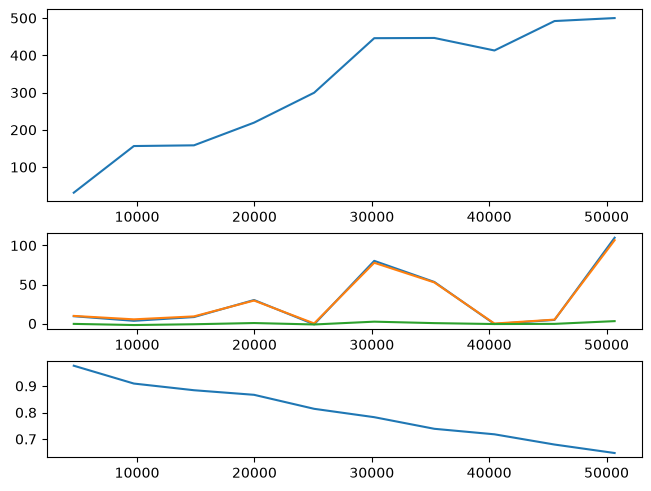

frames     : 50688
time       : 0
fps        : 700
reward     : 500.00
lr         : 0.000475
loss       : 109.933
critic_loss: 106.802
actor_loss : 3.141
std        : 0.647
clip_range : 0.100
vf_coef    : 0.500
std_coef   : 1.000
> Max reward target reached!


In [6]:
ppo.learn(max_frames, max_rewards=max_rewards, num_steps=num_steps, num_envs=num_envs, batch_size=batch_size,
          ppo_epochs=ppo_epochs, clip_range=clip_range, lr=lr, vf_coef=vf_coef, ent_coef=ent_coef,
          gamma=gamma, lam=lam, clip_grad_norm=clip_grad_norm, std_decay=std_decay, clip_log_std=clip_log_std,
          log_every=log_every, log_file=log_file, test_env=make_test_env(),runs_for_episode=runs_for_episode, test_episodes=test_episodes)

In [7]:
del ppo

In [8]:
ppo = PPO(make_env, device='cpu')

In [9]:
ppo.load(log_file)

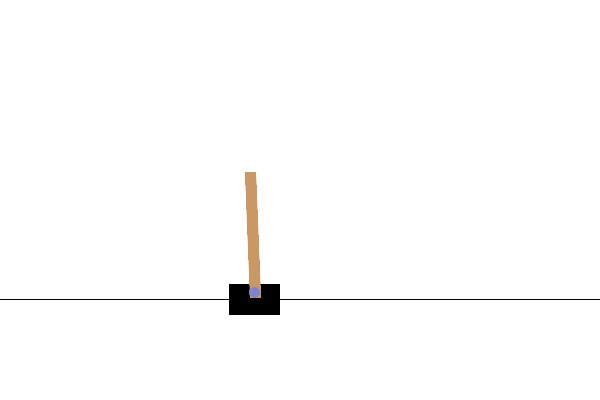

Mean reward over 1 episodes = 500.000000


In [10]:
env = make_env(render_mode='rgb_array')()
runs_for_episode = 1
n_episode = 1

mean_reward = run_test_env(env=env, model=ppo, runs_for_episode=runs_for_episode, n_episodes=n_episode, vis=True, deterministic=False)
env.close()

print('Mean reward over %i episodes = %f' % (n_episode, mean_reward))